In [1]:
import sys
from google.colab import drive

drive.mount('/content/drive')
sys.path.append('/content/drive/MyDrive/data')

Mounted at /content/drive


In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from data_utils import (
    CLASSES, DEFAULT_SIZE, make_augmentation, make_datasets,
    list_image_files, compute_class_weights,
)


In [3]:
augment = make_augmentation(rotation=0.03, zoom=0.1, translation=0.1, seed=42)

datasets, classes = make_datasets(
    "/content/drive/MyDrive/data/Data", batch_size=32, val_split=0.15, test_split=0.15,
    seed=42, normalize=True, augmentation=augment)

train_ds, val_ds, test_ds = datasets["train"], datasets["val"], datasets["test"]

In [4]:
print("classes:", classes)
for name, ds in datasets.items():
    print(f"{name:5s}: {int(tf.data.experimental.cardinality(ds).numpy())} lots")

for images, labels in train_ds.take(1):
    print("batch:", images.shape, images.dtype,
          "| labels:", labels.shape, labels.dtype)



classes: ('glioma', 'meningioma', 'notumor', 'pituitary')
train: 154 lots
val  : 33 lots
test : 33 lots
batch: (32, 224, 224, 3) <dtype: 'float32'> | labels: (32,) <dtype: 'int64'>


## Now we start by making the actual model

In [5]:
model = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),

    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Conv2D(128, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),

    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(4, activation="softmax"),
])

## Now we attach the params


In [6]:
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

In [7]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 4)              │           516 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,476 (42.61 MB)

 Trainable params: 11,169,476 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

## Now we can launch the actual Training

In [8]:
history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=20,
)

model.evaluate(test_ds)

Epoch 1/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 640s 4s/step - accuracy: 0.5454 - loss: 1.0489 - val_accuracy: 0.5721 - val_loss: 1.1956
Epoch 2/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 48s 314ms/step - accuracy: 0.7095 - loss: 0.7377 - val_accuracy: 0.7372 - val_loss: 0.7475
Epoch 3/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 82s 318ms/step - accuracy: 0.7410 - loss: 0.6554 - val_accuracy: 0.6992 - val_loss: 0.7985
Epoch 4/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 48s 312ms/step - accuracy: 0.7571 - loss: 0.6168 - val_accuracy: 0.7751 - val_loss: 0.6222
Epoch 5/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 83s 319ms/step - accuracy: 0.7636 - loss: 0.5675 - val_accuracy: 0.7761 - val_loss: 0.6566
Epoch 6/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 49s 315ms/step - accuracy: 0.7966 - loss: 0.5263 - val_accuracy: 0.8245 - val_loss: 0.4566
Epoch 7/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 82s 316ms/step - accuracy: 0.8124 - loss: 0.4763 - val_accuracy: 0.6841 - val_loss: 1.0781
Epoch 8/20
154/154 ━━━━━━━━━━━━━━━━━━━━ 82s 315ms/step - accuracy: 0.8159 - loss: 0.4

[0.2690224051475525, 0.9127134680747986]

In [13]:
import os
save_dir = "/content/drive/MyDrive/data/models"
os.makedirs(save_dir, exist_ok=True)
model_path = os.path.join(save_dir, "mri_cnn_model3.keras")
model.save(model_path)

print(f"Model successfully saved to: {model_path}")

Model successfully saved to: /content/drive/MyDrive/data/models/mri_cnn_model3.keras


## 1. Callback Configuration (ModelCheckpoint, BackupAndRestore, EarlyStopping)

In [10]:
import os
import tensorflow as tf

backup_dir = "/content/drive/MyDrive/data/models/backup"
checkpoint_path = "/content/drive/MyDrive/data/models/best_mri_cnn_model.keras"

os.makedirs(backup_dir, exist_ok=True)

callbacks = [
    tf.keras.callbacks.ModelCheckpoint(
        filepath=checkpoint_path,
        monitor='val_loss',
        save_best_only=True,
        mode='min',
        verbose=1
    ),
    tf.keras.callbacks.BackupAndRestore(
        backup_dir=backup_dir
    ),
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss',
        patience=5,
        restore_best_weights=True,
        verbose=1
    )
]

## 2. Model Re-training with Callbacks

In [11]:
model_callbacks = tf.keras.Sequential([
    tf.keras.Input(shape=(224, 224, 3)),
    tf.keras.layers.Conv2D(32, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(64, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Conv2D(128, 3, activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(4, activation="softmax"),
])

model_callbacks.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

history_cb = model_callbacks.fit(
    train_ds,
    validation_data=val_ds,
    epochs=25,
    callbacks=callbacks
)

Epoch 1/25
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 338ms/step - accuracy: 0.4702 - loss: 1.2087
Epoch 1: val_loss improved from None to 0.94401, saving model to /content/drive/MyDrive/data/models/best_mri_cnn_model.keras

Epoch 1: finished saving model to /content/drive/MyDrive/data/models/best_mri_cnn_model.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 60s 364ms/step - accuracy: 0.5663 - loss: 1.0234 - val_accuracy: 0.6546 - val_loss: 0.9440
Epoch 2/25
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 314ms/step - accuracy: 0.6963 - loss: 0.7735
Epoch 2: val_loss improved from 0.94401 to 0.89226, saving model to /content/drive/MyDrive/data/models/best_mri_cnn_model.keras

Epoch 2: finished saving model to /content/drive/MyDrive/data/models/best_mri_cnn_model.keras
154/154 ━━━━━━━━━━━━━━━━━━━━ 52s 336ms/step - accuracy: 0.7116 - loss: 0.7423 - val_accuracy: 0.6869 - val_loss: 0.8923
Epoch 3/25
154/154 ━━━━━━━━━━━━━━━━━━━━ 0s 358ms/step - accuracy: 0.7311 - loss: 0.6750
Epoch 3: val_loss improved from 0.89226 to 0.59291, s

## 3. Training Curves Visualization and Interpretation

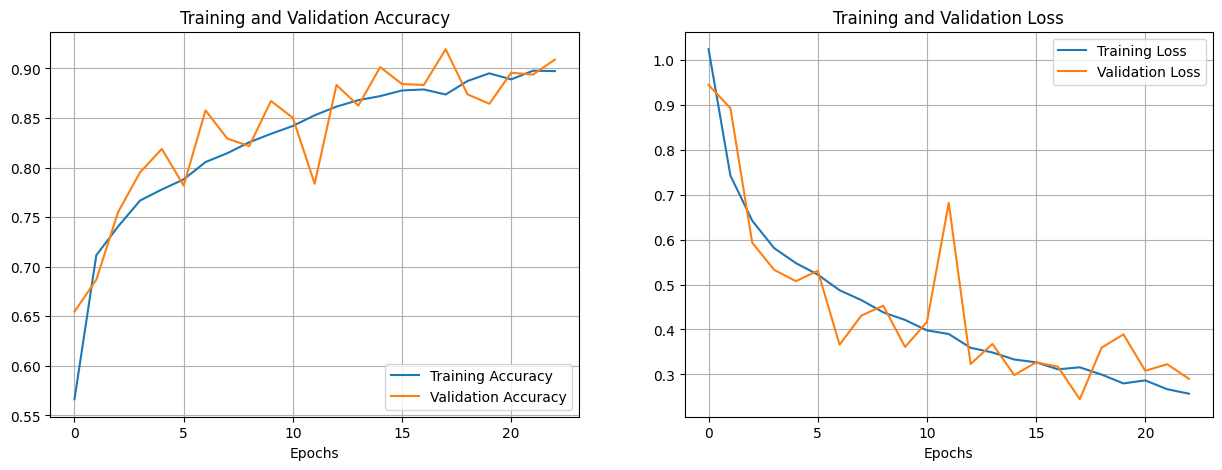

In [12]:
import matplotlib.pyplot as plt

acc = history_cb.history['accuracy']
val_acc = history_cb.history['val_accuracy']
loss = history_cb.history['loss']
val_loss = history_cb.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(15, 5))

plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.grid(True)

plt.show()